# Climate of India

This notebook uses varunayan to look at four parts of the climate of India:

- The temperature trend from 1941 to 2024, from [ERA5](https://www.ecmwf.int/en/forecasts/dataset/ecmwf-reanalysis-v5).
- The monsoon: the month of peak rainfall and the annual rainfall in each grid cell, from ERA5.
- Climate extremes: the hottest day (TXx) and the largest 1-day rainfall (Rx1day) of each year, from [HadEX3](https://www.metoffice.gov.uk/hadobs/hadex3/).
- India among other countries: the 2024 seasonal cycle of India and seven other countries, from ERA5.

ERA5 needs a CDS API key in `~/.cdsapirc`. HadEX3 downloads without credentials.

In [1]:
import pandas as pd

import varunayan as v

states = v.load_india_boundaries()

✓ CDS API configuration is already set up and valid.


## Temperature trend

`era5ify_geojson` gets the yearly mean 2 m temperature (°C) for each grid cell inside India, from 1941 to 2024. The [LGD state boundaries](https://geo.bharatviz.org/) give the region. `level="union"` keeps all the grid cells inside the union of the states.

In [2]:
era5 = v.era5ify_geojson(
    request_id="india_t2m_yearly",
    variables=["2m_temperature"],
    start_date="1941-01-01",
    end_date="2024-12-31",
    json_file="https://geo.bharatviz.org/geojsons/admin/India-geodata-lgd-states.geojson",
    frequency="yearly",
    level="union",
)
era5.head()

Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


...

Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


Found 3 invalid geometries. Attempting repair...


,datetime,latitude,longitude,variable,value,year
0,1941-01-01,7.00,93.75,t2m,26.498140,1941
1,1941-01-01,8.25,77.25,t2m,25.294527,1941
2,1941-01-01,8.25,77.50,t2m,25.742769,1941
3,1941-01-01,8.25,77.75,t2m,26.533133,1941
4,1941-01-01,8.50,77.00,t2m,24.730725,1941


`spatial_mean` averages the grid cells for each year. It weights each cell by the cosine of its latitude, so that each cell counts in proportion to its area. `anomaly` subtracts the 1941 to 2024 mean from each year. A positive anomaly is a year warmer than the mean.

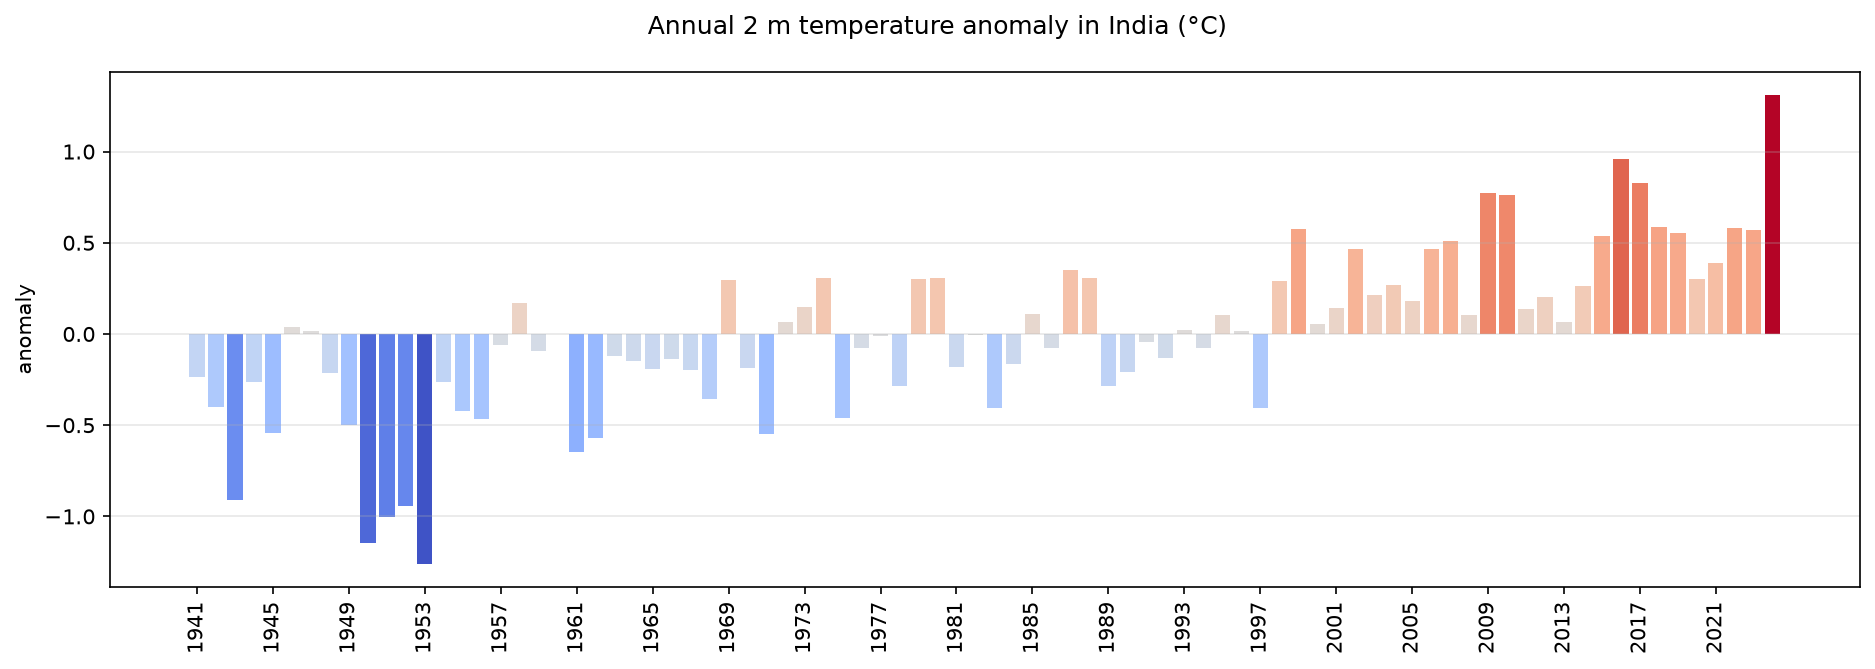

In [3]:
india = v.spatial_mean(era5, "value", by="year").rename(columns={"value": "t2m"})
india["anomaly"] = v.anomaly(india, "t2m")
v.plot_bars(
    india, x="year", y="anomaly", title="Annual 2 m temperature anomaly in India (°C)"
)

Most years before 1980 are cooler than the mean (30 of 39 years). After 1990, 30 of 35 years are warmer than the mean. The warmest years are 2016 and 2024, approximately 1 °C above the mean. Over the full period, the temperature increases by approximately 0.14 °C in each decade.

## Monsoon

`era5ify_bbox` gets the monthly total precipitation (mm) at 0.25° for a box around India, from 2000 to 2024. `peak_month` averages each calendar month over all years. Then it gives the month with the largest mean and the sum of the 12 monthly means (`annual_total`) for each grid cell.

In [4]:
rain = v.era5ify_bbox(
    request_id="tp_india_2000_2024",
    variables=["total_precipitation"],
    start_date="2000-01-01",
    end_date="2024-12-31",
    north=37.1,
    south=6.3,
    east=97.4,
    west=68.1,
    frequency="monthly",
    resolution=0.25,
    verbosity=0,
)
peak = v.peak_month(rain[rain.variable == "tp"], "value")
peak.head()

,latitude,longitude,peak_month,peak_value,annual_total
0,6.5,68.25,5,210.653458,1426.810951
1,6.5,68.50,5,213.247986,1433.043556
2,6.5,68.75,5,217.526474,1451.262016
3,6.5,69.00,5,220.094986,1475.256615
4,6.5,69.25,5,217.734604,1473.998604


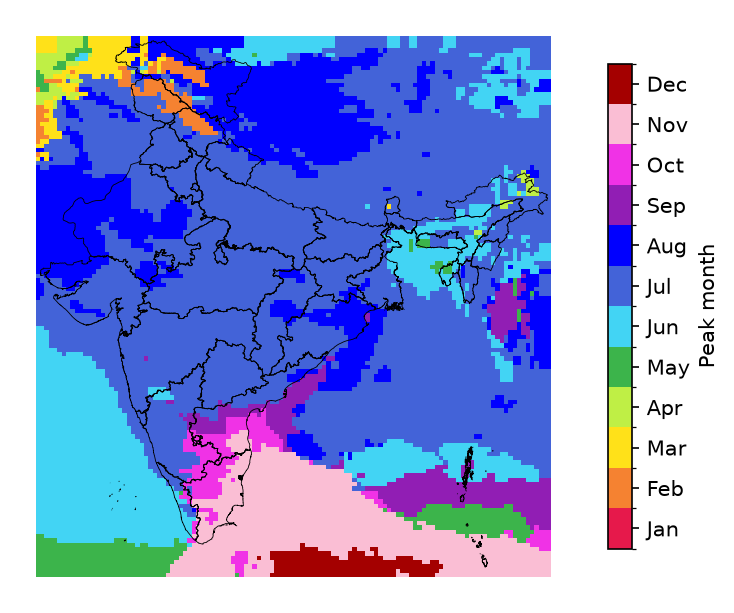

In [5]:
v.plot_map(
    peak, "peak_month", months=True, boundaries=states, legend_title="Peak month"
)

July is the month of peak rainfall in 70 % of the grid cells, and August in 14 %. On the coast of Tamil Nadu and in Sri Lanka, the peak is in October or November, from the northeast monsoon. North of 32° N, some cells have their peak in February or March, from western disturbances. Other cells there have their peak in July or August.

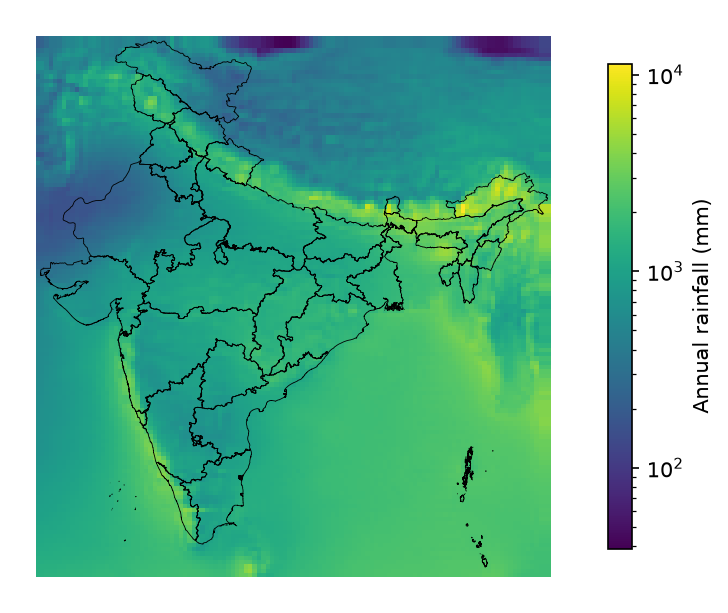

In [6]:
v.plot_map(
    peak,
    "annual_total",
    log=True,
    boundaries=states,
    legend_title="Annual rainfall (mm)",
)

The annual total changes from approximately 160 mm in the Thar Desert to more than 11 000 mm in Arunachal Pradesh. In 216 grid cells, the total is more than 3000 mm. Most of these cells are in the northeast, and most of the other cells are on the west coast. The map uses a log scale because the range is large.

## Climate extremes

[HadEX3](https://www.metoffice.gov.uk/hadobs/hadex3/) from the Met Office Hadley Centre gives 29 ETCCDI climate extreme indices on a 1.25° x 1.875° grid. The data is for 1901 to 2018 (Dunn et al. 2020, doi:10.1029/2019JD032263). We use two indices:

- TXx: the highest daily maximum temperature of each year (°C).
- Rx1day: the largest rainfall total in one day of each year (mm).

Each call downloads a gzipped NetCDF file (approximately 15 MB) one time and keeps it in a local cache. The number of grid cells with Rx1day data drops sharply after 2013, so the Rx1day series stops in 2013.

In [7]:
box = dict(north=37, south=6, east=98, west=68)
txx = v.hadex3_bbox(
    index="TXx", start_year=1951, end_year=2018, frequency="annual", **box
)
rx1day = v.hadex3_bbox(
    index="Rx1day", start_year=1951, end_year=2013, frequency="annual", **box
)
txx.head()

,year,latitude,longitude,value,index
0,1951,24.375,68.4375,43.916111,TXx
1,1952,24.375,68.4375,44.627647,TXx
2,1953,24.375,68.4375,41.034256,TXx
3,1954,24.375,68.4375,41.039726,TXx
4,1955,24.375,68.4375,43.679390,TXx


`spatial_mean` gives the area-weighted mean over the grid cells of India for each year. The LOWESS line shows the trend.

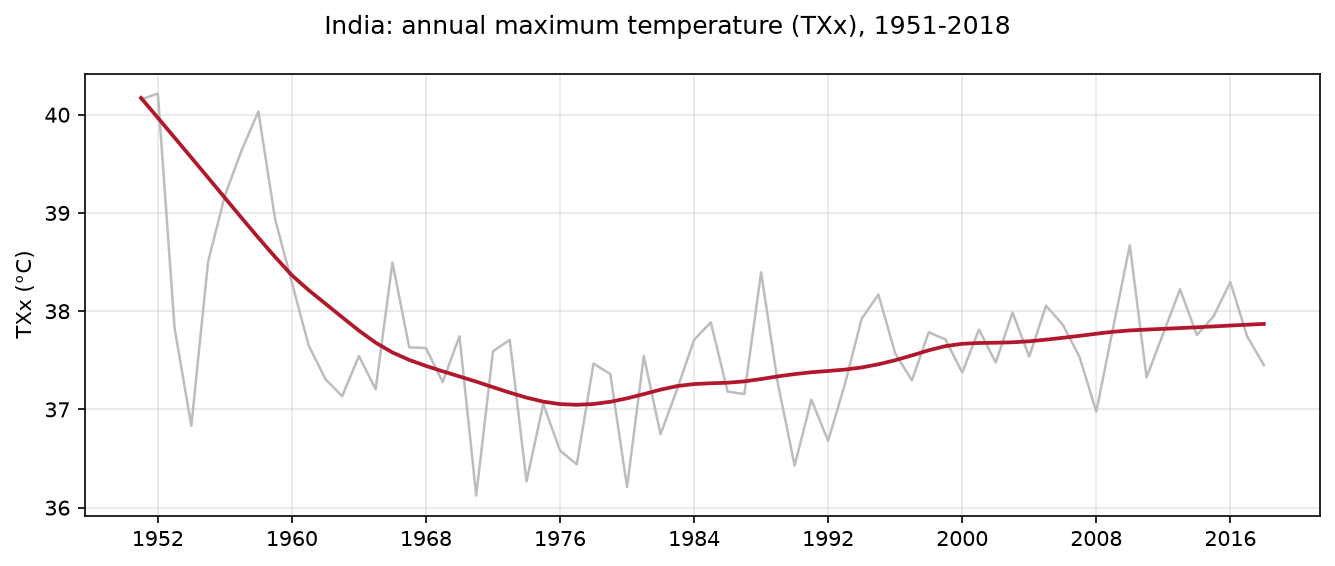

In [8]:
v.plot_series(
    v.spatial_mean(txx, "value", by="year"),
    x="year",
    y="value",
    smooth="lowess",
    span=0.3,
    ylabel="TXx (°C)",
    title="India: annual maximum temperature (TXx), 1951-2018",
)

The mean TXx over India does not increase. It is approximately 38.3 °C in 1951-1970, 37.1 °C in 1971-1990 and 37.7 °C in 1991-2018. The linear trend is approximately -0.1 °C in each decade.

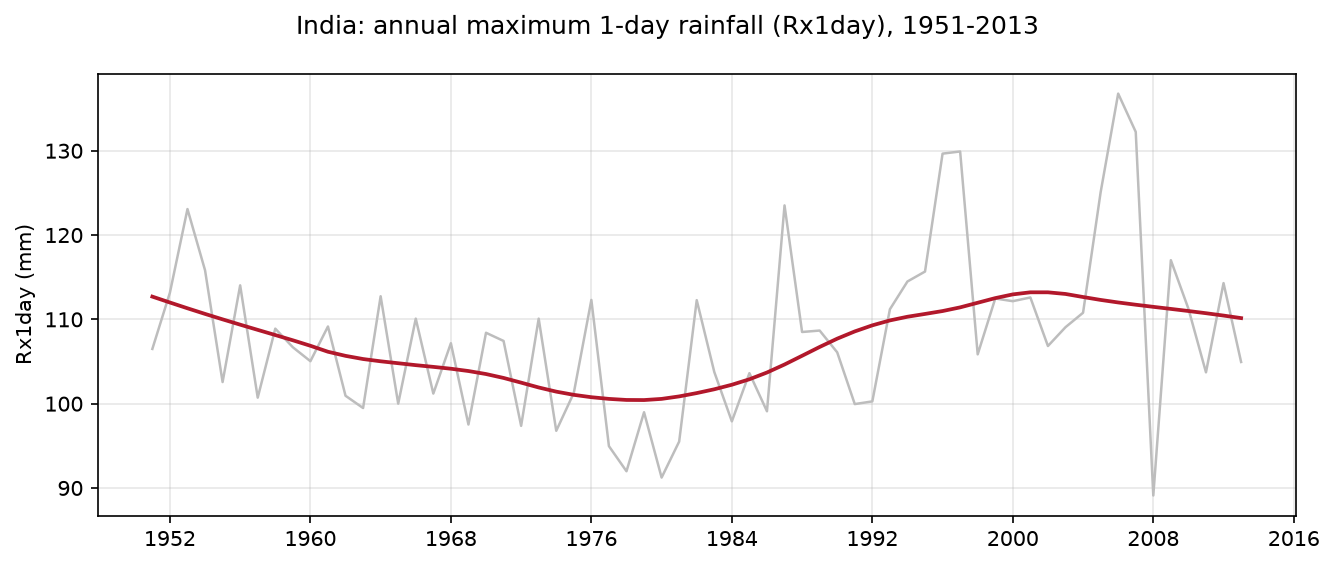

In [9]:
v.plot_series(
    v.spatial_mean(rx1day, "value", by="year"),
    x="year",
    y="value",
    smooth="lowess",
    span=0.35,
    ylabel="Rx1day (mm)",
    title="India: annual maximum 1-day rainfall (Rx1day), 1951-2013",
)

The mean Rx1day is different in each year, between approximately 89 mm and 137 mm. The highest value is in 2006. The LOWESS line shows no clear trend from 1951 to 2013.

The map shows the mean annual TXx in each grid cell for three periods: 1951-1970, 1971-1990 and 1991-2018. The three panels use one color scale.

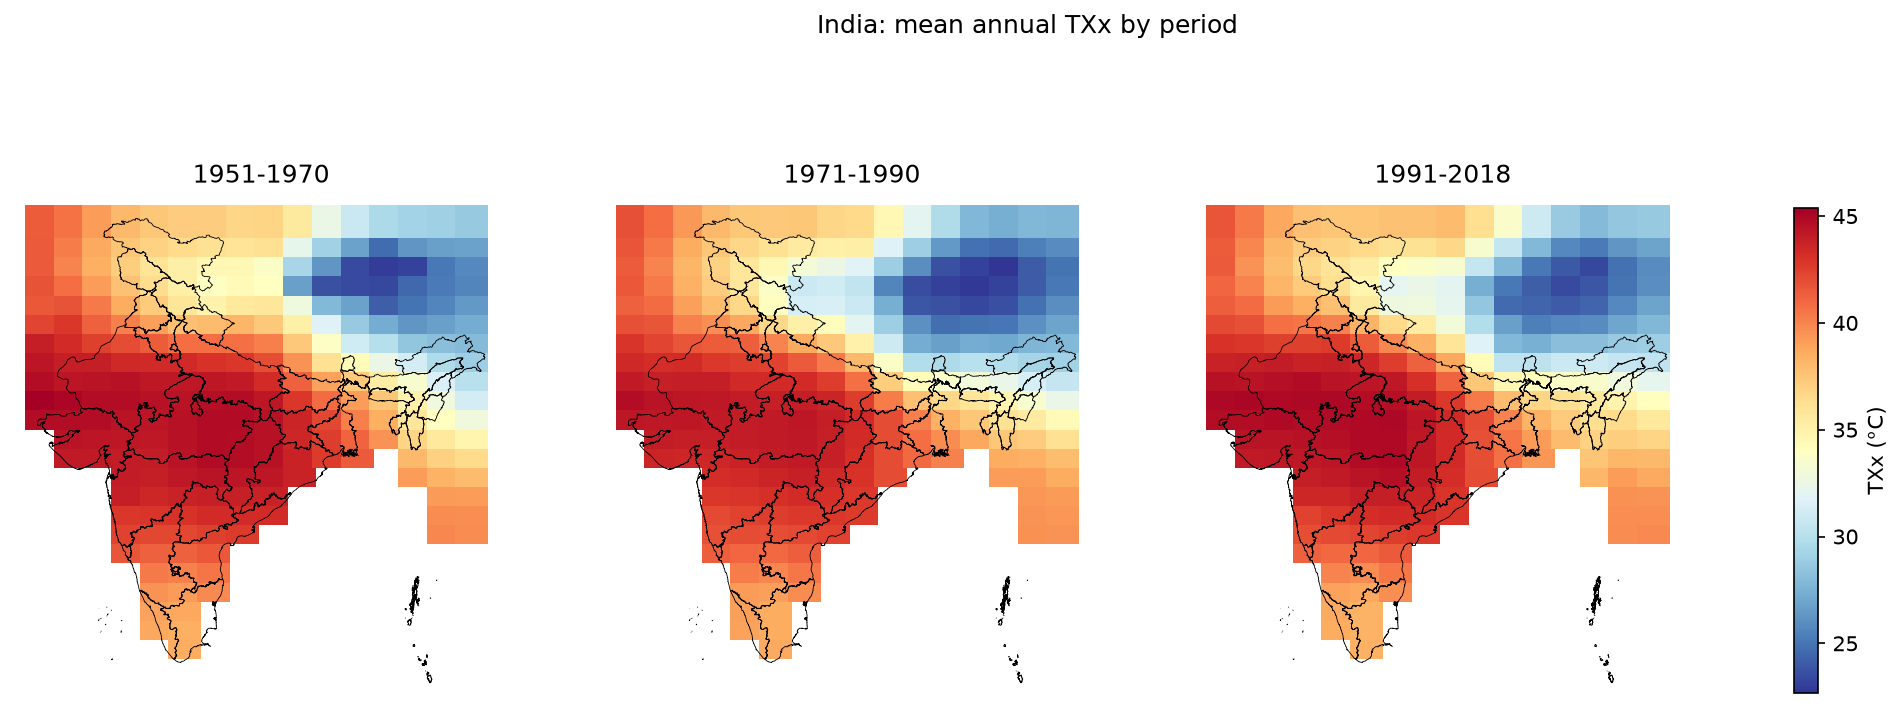

In [10]:
txx["period"] = pd.cut(
    txx.year,
    bins=[1950, 1970, 1990, 2018],
    labels=["1951-1970", "1971-1990", "1991-2018"],
)
periods = txx.groupby(
    ["period", "latitude", "longitude"], observed=True, as_index=False
)["value"].mean()
v.plot_map(
    periods,
    "value",
    facet="period",
    boundaries=states,
    cmap="RdYlBu_r",
    legend_title="TXx (°C)",
    title="India: mean annual TXx by period",
)

From 1951-1970 to 1991-2018, TXx increases in the northeast, by up to 2.8 °C. TXx decreases in Nepal and in the south of Tibet, by up to 6 °C. Only 44 % of the cells are warmer in the last period than in the first period. HadEX3 has few stations in the Himalaya, so the values there are less reliable.

## India among other countries

`get_era5_country_temperature` finds a country boundary in [Natural Earth](https://www.naturalearthdata.com/) data and downloads the monthly ERA5 2 m temperature (°C). It returns the national mean with cosine-latitude area weights. The function takes one country, so we call it for each country and join the results. We compare India with three South Asian and four European countries for 2024.

In [11]:
regions = {
    "France": "Europe",
    "Germany": "Europe",
    "Spain": "Europe",
    "Norway": "Europe",
    "India": "South Asia",
    "Pakistan": "South Asia",
    "Bangladesh": "South Asia",
    "Nepal": "South Asia",
}
temps = pd.concat(
    v.get_era5_country_temperature(c, "2024-01-01", "2024-12-31").assign(
        country=c, region=r
    )
    for c, r in regions.items()
)
temps.head()

,year,month,temperature_mean,country,region
0,2024,1,7.587794,France,Europe
1,2024,2,10.460944,France,Europe
2,2024,3,11.331961,France,Europe
3,2024,4,12.878803,France,Europe
4,2024,5,15.399574,France,Europe


In the heat map, each row is a country and each column is a month.

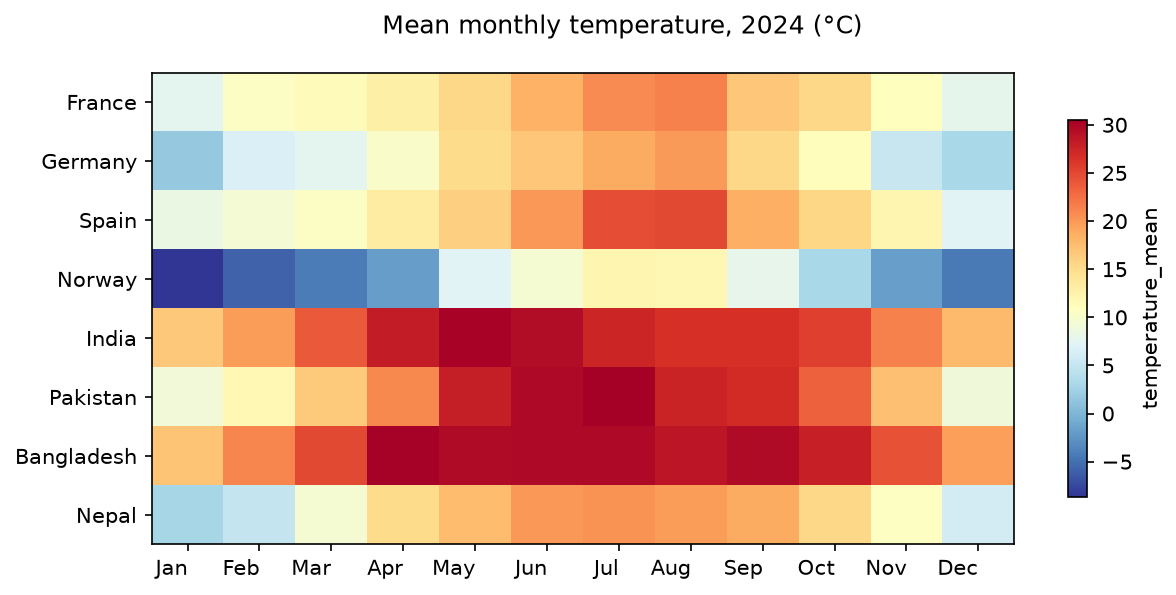

In [12]:
v.plot_heatmap(
    temps,
    x="month",
    y="country",
    value="temperature_mean",
    title="Mean monthly temperature, 2024 (°C)",
)

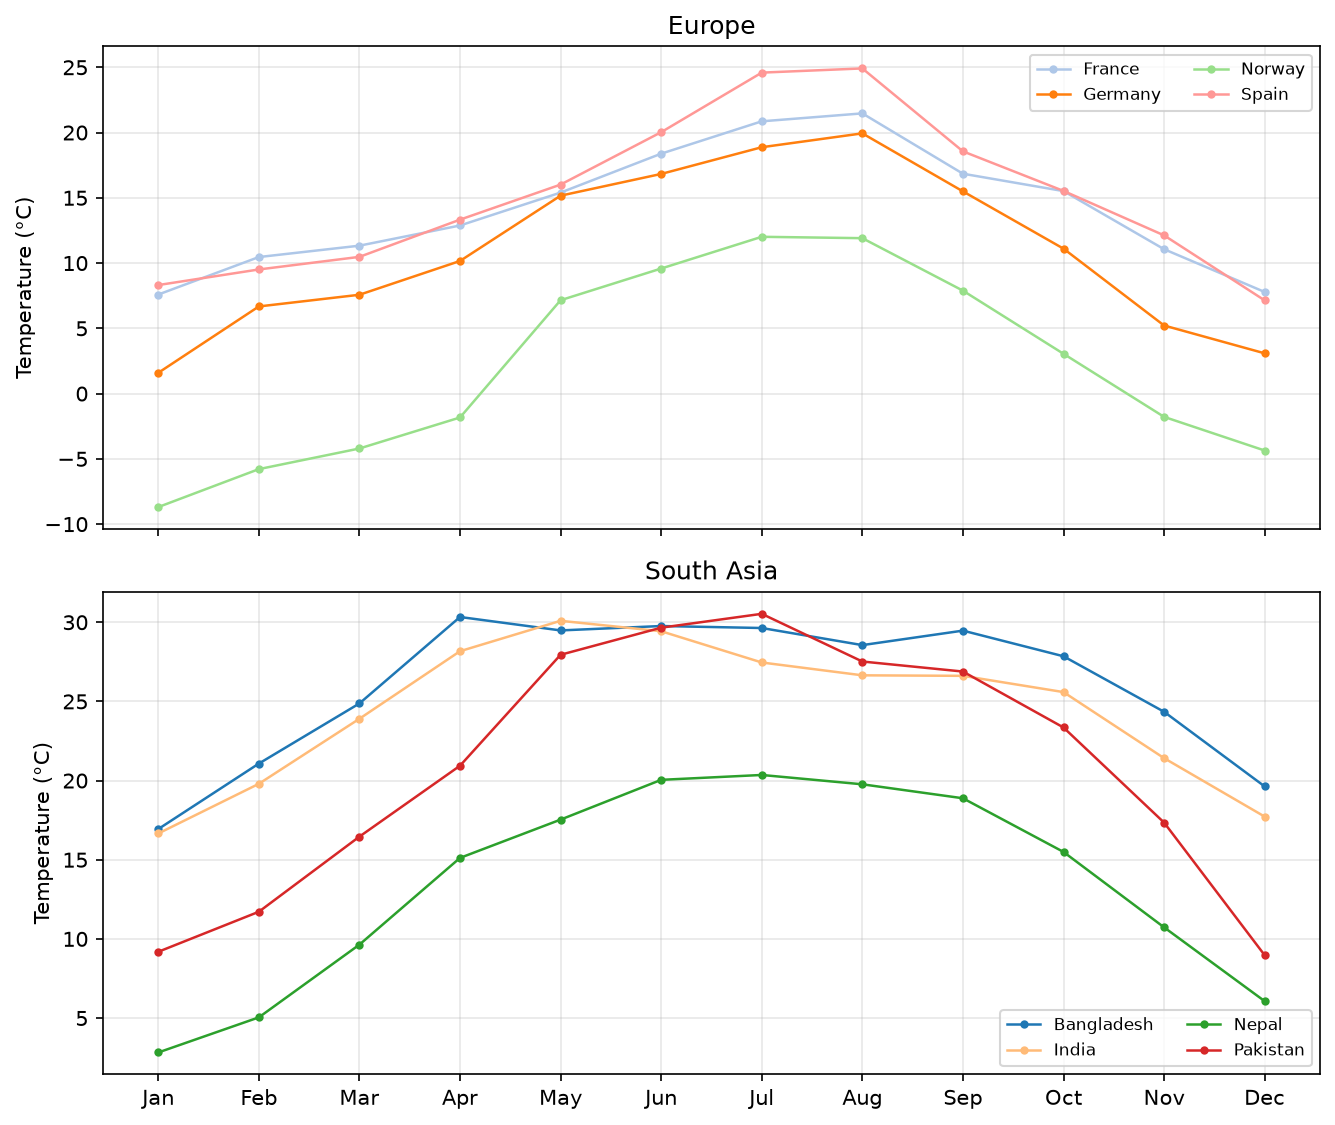

In [13]:
v.plot_series(
    temps,
    x="month",
    y="temperature_mean",
    by="country",
    facet="region",
    ylabel="Temperature (°C)",
)

The four European countries have a large seasonal cycle, with cold winters and a peak in July. Norway is the coldest country in all months. Bangladesh, India and Pakistan are warm all year and are hottest before the monsoon, in May and June. Nepal is much cooler than its neighbors, because a large part of the country is in the Himalaya.